In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

Here we use the `bayesbay.prior.UniformPrior` to define the prior for invert parameters.

Access this link for more details (https://bayes-bay.readthedocs.io/en/latest/api/generated/bayesbay.prior.UniformPrior.html#bayesbay.prior.UniformPrior)

In [2]:
d = np.array([0, 500, 1000, 2000, 3500, 5000])
vs = np.array([0.1, 0.8, 1.5, 2.7, 2.8, 3.0])
offset = 2.0
perturb_std_in_percent = 0.05
vs_min = np.maximum(vs - offset, 0.0)
vs_max = np.minimum(vs + offset, 4.5)
vs_std = np.clip((vs_max - vs_min) * perturb_std_in_percent, 0.02, 0.5)

Text(0.5, 0, 'Vs std (km/s)')

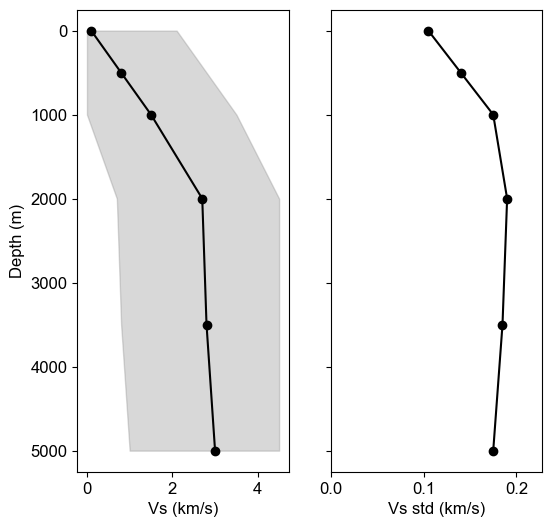

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(6, 6), sharey=True)

ax[0].plot(vs, d, 'o-', color='black', label='Vs')
ax[0].fill_betweenx(d, vs_min, vs_max, color='gray', alpha=0.3, label='Vs range')
ax[0].invert_yaxis()
ax[0].set_xlabel('Vs (km/s)')
ax[0].set_ylabel('Depth (m)')

ax[1].plot(vs_std, d, 'o-', color='black', label='Vs std')
ax[1].set_xlim(0, np.max(vs_std) * 1.2)
ax[1].set_xlabel('Vs std (km/s)')

In [4]:
with open("src_rec/cluster0_vs_init.mod", "w") as f:
    f.write("# Depth (m) Vs (km/s) Vs_min (km/s) Vs_max (km/s) Vs_std (km/s)\n")
    for i in range(len(d)):
        f.write(f"{d[i]:.6f} {vs[i]:.6f} {vs_min[i]:.6f} {vs_max[i]:.6f} {vs_std[i]:.6f}\n")

with open("src_rec/cluster1_vs_init.mod", "w") as f:
    f.write("# Depth (m) Vs (km/s) Vs_min (km/s) Vs_max (km/s) Vs_std (km/s)\n")
    for i in range(len(d)):
        f.write(f"{d[i]:.6f} {vs[i]:.6f} {vs_min[i]:.6f} {vs_max[i]:.6f} {vs_std[i]:.6f}\n")